# Notebook 15 — Dataset 2 Population Surveillance

**Purpose:** Load the CDC Diabetes Surveillance System dataset and analyze population-level trends. Provide the public-health context required for the dashboard. 

**Inputs:** Raw Surveillance Dataset (`data/raw/export.csv`)

**Outputs:**
- Processed surveillance dataset (`data/processed/df2_surveillance.csv`)
- Surveillance figures (`results/surveillance/`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from src.config import *
from src.plotting import save_figure

seed_everything()

df2 = pd.read_csv(DATASET2_PATH)
print(f"Dataset 2 (Surveillance) shape: {df2.shape}")
df2.head()


Dataset 2 (Surveillance) shape: (13889, 16)


,Year,Topic,Indicator,Unit,Estimate,SE Estimate,Lower Limit,Upper Limit,Estimate Footnote,Data Source,Population,Age,Race,Sex,Education,Other Stratification
0,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,8.3,0.3,7.7,9,NaN,National Health Interview Survey (NHIS),All Ages,45-64,All,All,All,NaN
1,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,15.8,0.8,14.3,17.3,NaN,National Health Interview Survey (NHIS),All Ages,65-74,All,All,All,NaN
2,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,13.2,0.7,11.8,14.7,NaN,National Health Interview Survey (NHIS),All Ages,75+,All,All,All,NaN
3,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,1.2,0.1,1.1,1.4,NaN,National Health Interview Survey (NHIS),All Ages,0-44,All,All,All,NaN
4,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,4.4,0.1,4.2,4.6,NaN,National Health Interview Survey (NHIS),All Ages,Crude,All,All,All,NaN


## 15.1 Data Cleaning & Filtering

In [2]:
# Filter relevant columns and rows
# We are primarily interested in "Diagnosed Diabetes" prevalence overall or by Age/Sex
df2_clean = df2.copy()
print("Topics:", df2_clean['Topic'].unique())
print("Indicators:", df2_clean['Indicator'].unique())

# Drop rows where 'Estimate' is NaN
df2_clean = df2_clean.dropna(subset=['Estimate'])

# Focus on Percentage unit for consistency
df2_clean = df2_clean[df2_clean['Unit'] == 'Percentage']

# Create a clean version for the dashboard
os.makedirs(os.path.join(DATA_PROCESSED), exist_ok=True)
df2_clean.to_csv(os.path.join(DATA_PROCESSED, "df2_surveillance.csv"), index=False)
print("✓ Cleaned surveillance data saved.")


Topics: <ArrowStringArray>
['Burden/Magnitude']
Length: 1, dtype: str
Indicators: <ArrowStringArray>
[          'Diagnosed Diabetes', 'Age at Diagnosis of Diabetes',
    'Diagnosed Type 1 Diabetes',    'Diagnosed Type 2 Diabetes',
         'Duration of Diabetes',     'Newly Diagnosed Diabetes']
Length: 6, dtype: str
✓ Cleaned surveillance data saved.


## 15.2 Time Series / Trend Analysis

In [3]:
# Overall prevalence over time
overall = df2_clean[(df2_clean['Age'] == 'All') & (df2_clean['Sex'] == 'All') & (df2_clean['Race'] == 'All') & (df2_clean['Indicator'] == 'Diagnosed Diabetes')]

if not overall.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(overall['Year'], overall['Estimate'], marker='o', color='red', lw=2)
    ax.fill_between(overall['Year'], overall['Lower Limit'], overall['Upper Limit'], color='red', alpha=0.2)
    ax.set_title("Overall Diagnosed Diabetes Prevalence Over Time (Percentage)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Estimate (%)")
    os.makedirs(RESULTS_SURV, exist_ok=True)
    save_figure(fig, os.path.join(RESULTS_SURV, "15_trend_overall.png"))
    plt.show()
else:
    print("Warning: Missing overall group data for simple trend plot.")


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/surveillance\15_trend_age.png


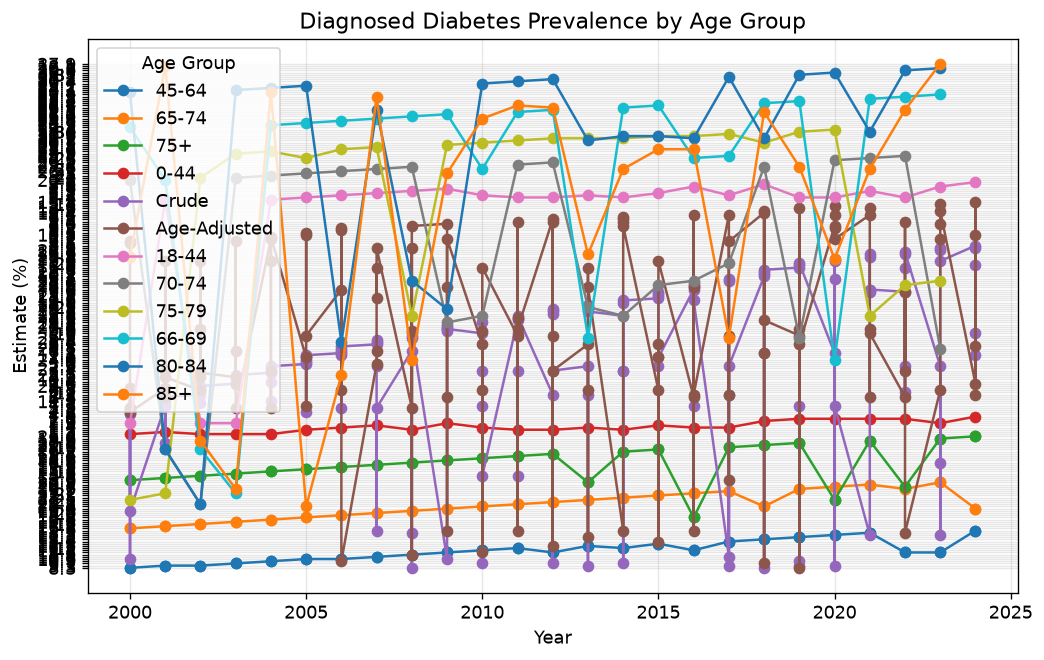

In [4]:
# Age group trends
age_groups = df2_clean[(df2_clean['Age'] != 'All') & (df2_clean['Sex'] == 'All') & (df2_clean['Race'] == 'All') & (df2_clean['Indicator'] == 'Diagnosed Diabetes')]

if not age_groups.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    for age_grp in age_groups['Age'].unique():
        sub = age_groups[age_groups['Age'] == age_grp].sort_values("Year")
        ax.plot(sub['Year'], sub['Estimate'], marker='o', label=age_grp)
    ax.set_title("Diagnosed Diabetes Prevalence by Age Group")
    ax.set_xlabel("Year")
    ax.set_ylabel("Estimate (%)")
    ax.legend(title="Age Group")
    save_figure(fig, os.path.join(RESULTS_SURV, "15_trend_age.png"))
    plt.show()


## 15.3 Conclusion

**Surveillance Findings:**
1. The secondary dataset tracks population-level "Diagnosed Diabetes" over multiple years.
2. Older age groups exhibit significantly higher prevalence, aligning closely with the individual-level findings (where older individuals had much higher probability of being in the Diabetes class).
3. The cleaned surveillance data (`df2_surveillance.csv`) is now ready for the dashboard to provide the macro-level context.

**Next:** Notebook 16 — Integrated Public Health Analysis
